# Lab 8: full-field cavity learning across Reynolds number

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab8_High_Re_Field_DeepONet.ipynb)

Predict complete velocity fields and inspect their physical discrepancies.
This new companion follows Lab 7. Earlier notebooks and the historical
Ghia-profile MLP are preserved. Run All audits saved models on CPU; it does not
start training or HPC jobs.

[Protocol](../../docs/CAVITY_FIELD_NEURAL_PROTOCOL.md) |
[Results](../../results/cavity_field_deeponet/README.md) |
[CFD audit](../../results/cavity_highre_ghia/README.md) |
[Related studies](../../docs/CAVITY_ALL_RE_NEURAL_LITERATURE.md)

## 1. What is being learned?

The target is our steady 2-D square-cavity velocity on a 513-by-513 grid,
with a constant moving lid and its corner discontinuity. This is a specified
numerical solution, not an exact mesh-independent field. Pressure is not predicted.

Ghia supplies sparse centreline observations, used here only for comparison.
Training labels are our full CFD fields. A branch maps a scalar Re to coefficients
of a fixed POD trunk. This restricted POD-DeepONet is not a data-free PINN or
an operator over arbitrary boundary functions. Every location of each held-out
Re stays outside fitting and model selection.

## Aim and route through this lab

**Aim.** Predict complete high-Re cavity velocity fields from Reynolds number
and compare a frozen POD-DeepONet with interpolation using the same training
information. Unlike Lab 6, this is a two-dimensional field experiment; unlike
Lab 9, its training labels are CFD fields.

The first three sections establish the whole-Re split, SVD representation,
validation-based architecture choice, and projection error that no branch
optimizer can remove. Sections 4–6 then compare retained test predictions:
inspect overlaid streamlines, signed velocity profiles, vorticity and recovered
pressure, with special attention to weak corner circulation. A smaller global
velocity norm does not guarantee a smaller derivative or corner error.

The optional CPU-fit cell now plots the **current validation** predictions and
their profiles, not just a numeric table. It does not alter the frozen result
package or fit on test targets. Its rank remains the frozen trunk rank; deeper
branches cannot create spatial modes absent from that trunk. New architecture
choices informed by the already published test images need fresh tests for a
new research claim.

Run All re-plots verified evidence on CPU. The historical-computing and solver
cost sections distinguish a measured present-day experiment from historical
context. Read the Lab 8 section of
[Lecture 4](../../lectures/week04_cavity_surrogates_deeponet.pdf), and include both
gains and deteriorations in your report.


In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

import json
from flowmllab import cavity_field_operator as op
from flowmllab import cavity_field_evidence as evidence
OUT = ROOT/'results/cavity_field_deeponet'
selection = json.loads((OUT/'frozen_selection.json').read_text())
display(pd.DataFrame([
    {'Role':'Training','Re':selection['train_re']},
    {'Role':'Validation','Re':selection['validation_re']},
    {'Role':'Test','Re':selection['test_re']}]))
assert not set(selection['train_re']) & set(selection['test_re'])
assert not set(selection['validation_re']) & set(selection['test_re'])
print('Selected:',selection['selected_configuration'],'POD rank:',selection['rank'])
cases, info = evidence.load(ROOT)

# Shared, array-driven figures; student outputs stay separate from frozen evidence.
from pathlib import Path
import os, sys
_w4_root = next(p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
                if (p/'flowmllab/week04_teaching_plots.py').is_file())
if str(_w4_root) not in sys.path: sys.path.insert(0, str(_w4_root))
from flowmllab import week04_teaching_plots as w4plots
W4_OUTPUT = Path(os.environ.get('FLOWMLLAB_W4_OUTPUT', str(_w4_root/'student_outputs/week04_current')))
W4_OUTPUT.mkdir(parents=True, exist_ok=True)
def save_current_figure(fig, name):
    fig.savefig(W4_OUTPUT/(name+'.png'), dpi=150, bbox_inches='tight')
    return fig


,Role,Re
0,Training,"[100, 250, 500, 750, 1000, 2500, 4000, 5000, 6..."
1,Validation,"[400, 6500]"
2,Test,"[3200, 7500]"


Selected: hybrid_2 POD rank: 10


## 2. Spatial representation, architecture and optimization

Stack both velocity components into $\mathbf q=[u_1,\ldots,u_N,v_1,\ldots,v_N]^T$.
The training mean $\overline{\mathbf q}$ and orthonormal POD modes form the trunk:

$$\widehat{\mathbf q}(Re)=\overline{\mathbf q}
 +\sum_{k=1}^{r}a_k(Re)\boldsymbol\phi_k,\qquad
 \mathbf a(Re)=\mathbf s\odot f_\theta(\log_{10}Re-3).$$

Here $N=513^2$, $r$ is the training-only rank, $\theta$ the tanh branch parameters,
and $\mathbf s$ a training-only coefficient scale. The training loss is

$$J(\theta)=\frac{1}{n_{\rm tr}r}\sum_{j=1}^{n_{\rm tr}}\sum_{k=1}^{r}
 [f_{\theta,k}(z_j)-a_{jk}/s_k]^2.$$

Global scaling uses one RMS for all coefficients. Per-mode scaling uses each
mode's RMS, emphasizing low-energy structures. This can improve details or
harm generalization; it is a hypothesis to test.

Adam adapts updates using gradient moments. L-BFGS approximates curvature from
recent parameter and gradient changes. The hybrid warms up with Adam then
refines one fixed full-batch objective. Line-search evaluations count toward
the same budget. Five layers do not automatically outperform two.

In [2]:
validation = pd.read_csv(OUT/'validation_scores.csv')
display(validation[['method','seed','Re','relative_l2','parameters','evaluations']])
display(validation.groupby(['method','Re'],sort=False).relative_l2.agg(['mean','min','max']))
display(pd.read_csv(OUT/'validation_baselines.csv'))

,method,seed,Re,relative_l2,parameters,evaluations
0,adam_2,7,400,0.005708,1450,4000
1,adam_2,7,6500,0.002582,1450,4000
2,adam_2,23,400,0.005873,1450,4000
3,adam_2,23,6500,0.002065,1450,4000
4,adam_2,61,400,0.005163,1450,4000
5,adam_2,61,6500,0.002392,1450,4000
6,hybrid_2,7,400,0.005466,1450,4000
7,hybrid_2,7,6500,0.000355,1450,4000
8,hybrid_2,23,400,0.003168,1450,4000
9,hybrid_2,23,6500,0.000238,1450,4000


mean       min       max
method                    Re                                
adam_2                    400   0.005581  0.005163  0.005873
                          6500  0.002346  0.002065  0.002582
hybrid_2                  400   0.004147  0.003168  0.005466
                          6500  0.000315  0.000238  0.000355
hybrid_5                  400   0.005555  0.003595  0.006772
                          6500  0.000212  0.000183  0.000229
hybrid_5_balanced         400   0.023839  0.015079  0.034741
                          6500  0.015978  0.011481  0.021312
hybrid_5_capacity_matched 400   0.040744  0.035017  0.043646
                          6500  0.026069  0.017912  0.037751

,method,Re,relative_l2,rmse_U,linf_U
0,linear_in_linear_Re,400,0.030152,0.006113,0.023525
1,linear_in_linear_Re,6500,0.002902,0.000627,0.004117
2,linear_in_log_Re,400,0.021946,0.004449,0.020870
3,linear_in_log_Re,6500,0.002005,0.000433,0.003427


## 3. Diagnose the basis before blaming the optimizer

The first nine-training-case round is retained in selection_round_1.
At validation Re=400, its optimal POD projection already had 3.2510% error.
No branch optimizer can remove that spatial-basis floor. Independent training
cases at Re=500 and 750 filled the low-Re gap. Validation/test cases and the
candidate budget remained unchanged. This amendment used validation, before
any neural test scoring; the benchmark physics was already disclosed.

The target projection is
$$\mathbf q_{\rm proj}=\overline{\mathbf q}+\Phi\Phi^T
(\mathbf q_{\rm true}-\overline{\mathbf q}).$$
It uses the true field and is a representation lower bound, not a predictor.

In [3]:
decision = json.loads((OUT/'selection_round_1/ROUND_DECISION.json').read_text())
display(pd.DataFrame([decision]))
display(pd.read_csv(OUT/'projection_lower_bound.csv'))

,reason,validation_projection_relative_l2,selected_validation_mean_relative_l2,added_training_re,unchanged_validation_re,unchanged_test_re,test_targets_opened_for_model_scoring,scope
0,Validation Re400 POD projection floor 3.251048...,"{'400': 0.032510483915755874, '6500': 3.822628...",0.020686,"[500, 750]","[400, 6500]","[3200, 7500]",False,Validation-driven training-data augmentation b...


,Re,relative_l2,rmse_U,linf_U
0,3200,0.000092,0.000020,0.000180
1,7500,0.000098,0.000021,0.000315


## 4. Matched-information tests and physical profiles

Both baselines interpolate exactly the training fields, linearly in Re or
log(Re). The convention is selected on validation; both test scores are shown.
Neural curves average the three predeclared seeds of the selected configuration,
rather than choosing the best test seed.

$$E_{\mathbf u}=\sqrt{\frac{\sum_i[(\widehat u_i-u_i)^2+
(\widehat v_i-v_i)^2]}{\sum_i(u_i^2+v_i^2)}}.$$

This measures vector discrepancy, not merely speed discrepancy, and avoids
pointwise division by zero velocity. The field plots share speed limits and
a linear vector-error scale. Signed centreline errors and actual Ghia samples
are retained; a cross marks the predeclared suspicious printed entry.

,method,Re,relative_l2,rmse_U,linf_U,u_relative_l2,v_relative_l2
15,selected_three_seed_mean,3200,0.000951,0.000206,0.001784,0.000932,0.000970
16,linear_in_Re,3200,0.008400,0.001816,0.009634,0.008293,0.008513
17,linear_in_log_Re,3200,0.005394,0.001166,0.007904,0.005095,0.005696
33,selected_three_seed_mean,7500,0.000844,0.000182,0.002056,0.000820,0.000868
34,linear_in_Re,7500,0.004703,0.001014,0.006795,0.004590,0.004818
35,linear_in_log_Re,7500,0.003139,0.000677,0.005334,0.002945,0.003330


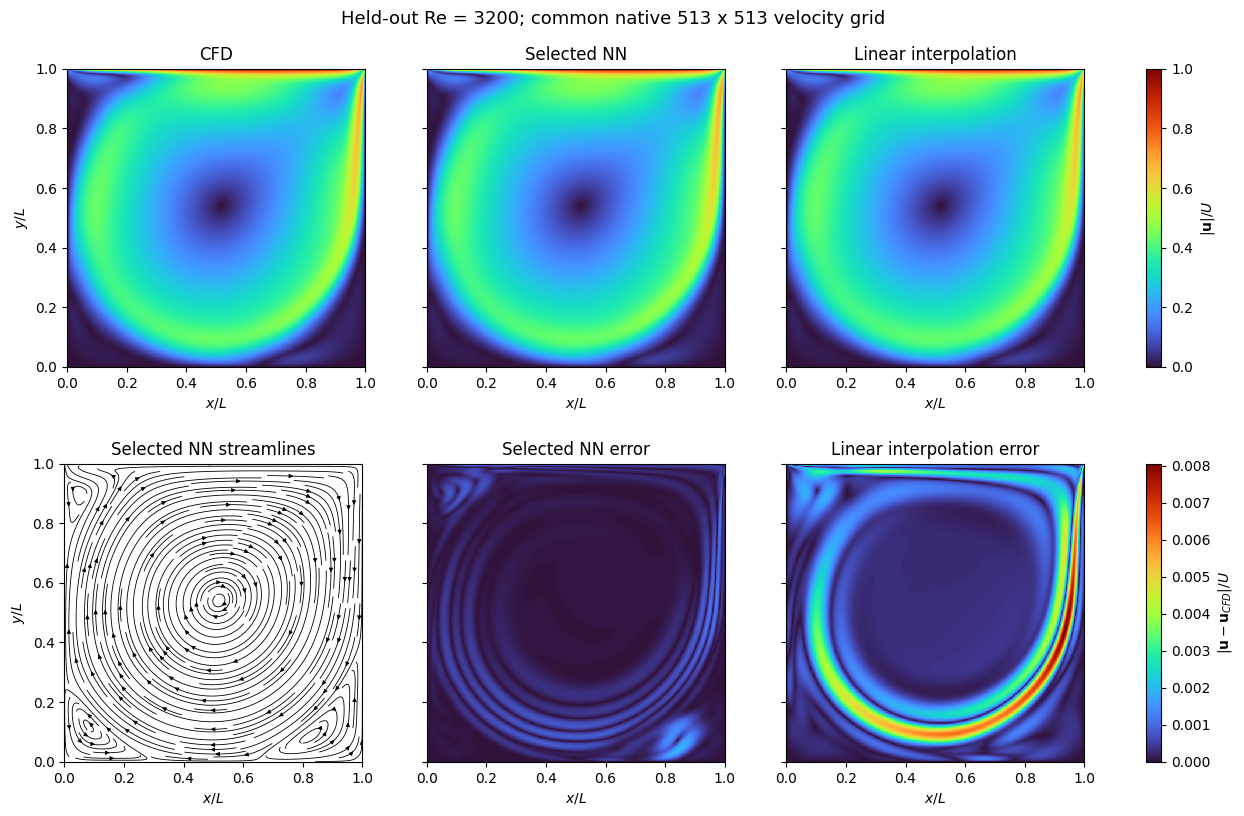

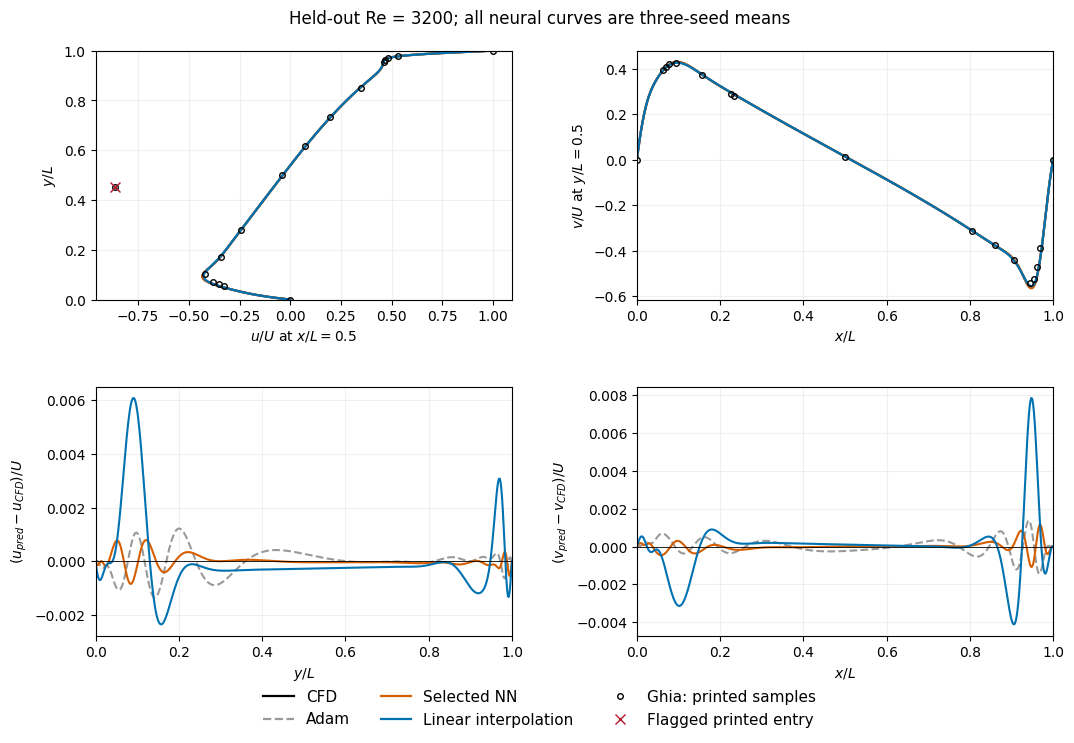

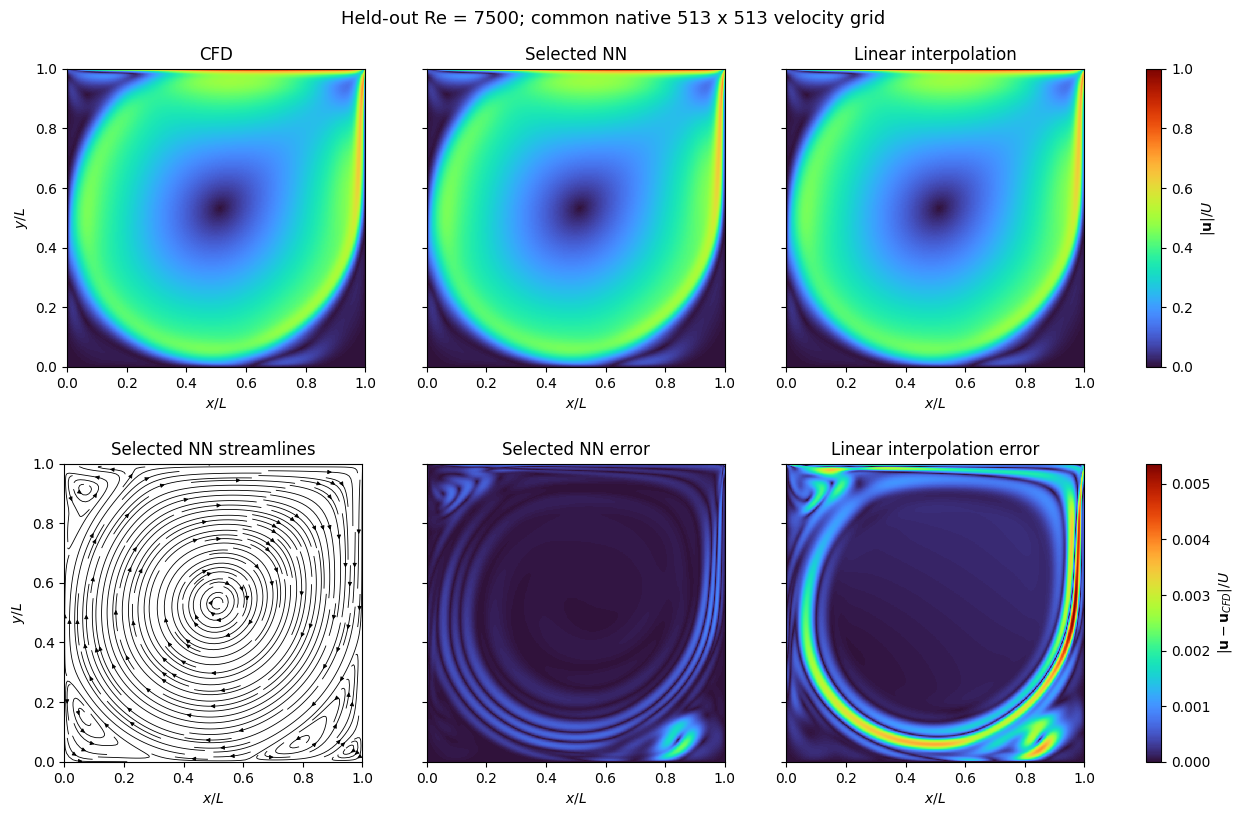

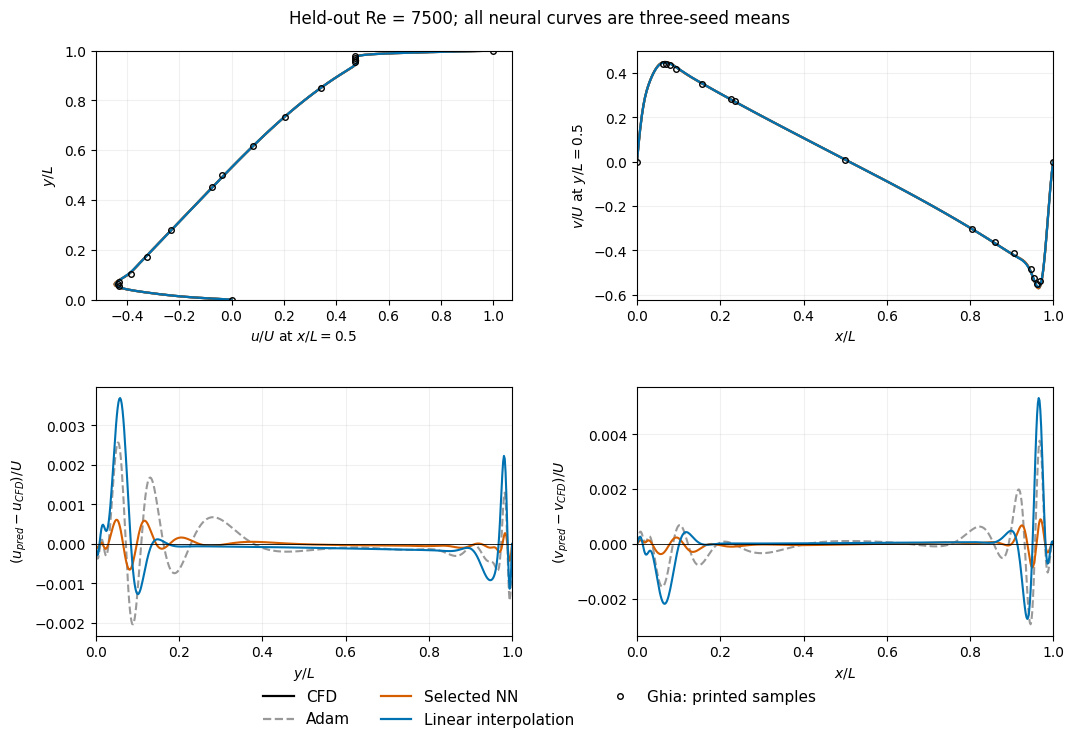

In [4]:
test_scores = pd.read_csv(OUT/'test_scores.csv')
reported = test_scores[test_scores.method.isin([
    'selected_three_seed_mean','linear_in_Re','linear_in_log_Re'])]
display(reported[['method','Re','relative_l2','rmse_U','linf_U',
                  'u_relative_l2','v_relative_l2']])
for reynolds, fields in cases.items():
    evidence.plot_fields(fields,reynolds)
    plt.show()
    evidence.plot_profiles(fields,reynolds)
    plt.show()

## 5. Physical constraints and numerical limits

Linear combinations preserve matched wall velocities and discrete continuity.
They generally do not satisfy nonlinear Navier-Stokes at a new Re.
Re-evaluate the vorticity-transport, Poisson, wall and continuity defects below.

Also compare surrogate error with 256-to-512 mesh sensitivity on common native
points. The mesh difference is not an exact-error bound or confidence interval.
It can exceed neural error; excellent agreement with one discretization does
not establish physical accuracy. A steady root does not establish stability.

In [5]:
physical = pd.DataFrame(evidence.diagnostics(cases))
display(physical[['Re','method','relative_velocity_l2','steady_vorticity_linf',
                  'poisson_linf','continuity_linf','wall_linf']])
mesh = pd.read_csv(ROOT/'results/cavity_highre_ghia/mesh_sensitivity.csv')
display(mesh[(mesh.cells==256)&mesh.Re.isin(op.TEST)][[
    'Re','cells','reference_cells','velocity_relative_l2','u_linf_U','v_linf_U']])

,Re,method,relative_velocity_l2,steady_vorticity_linf,poisson_linf,continuity_linf,wall_linf
0,3200,CFD,0.000000,4.920011e-10,3.244716e-11,2.842171e-14,0.000000e+00
1,3200,Selected NN,0.000951,7.975351e+02,7.508083e-11,1.419975e-13,6.912160e-11
2,3200,Linear interpolation,0.005394,2.060406e+03,5.746559e-11,1.274536e-13,4.251888e-11
3,3200,Adam,0.001463,5.553663e+02,7.453549e-11,1.221800e-13,4.547474e-12
4,7500,CFD,0.000000,7.270160e-09,3.140821e-11,2.842171e-14,0.000000e+00
5,7500,Selected NN,0.000844,2.961648e+02,5.707568e-11,1.211808e-13,4.331469e-11
6,7500,Linear interpolation,0.003139,1.329394e+03,5.152900e-11,1.194600e-13,4.547474e-12
7,7500,Adam,0.002679,1.093627e+03,4.620393e-11,1.336153e-13,3.865352e-12


,Re,cells,reference_cells,velocity_relative_l2,u_linf_U,v_linf_U
15,3200,256,512,0.020252,0.011273,0.015020
25,7500,256,512,0.047195,0.026665,0.036192


## 6. Overlaid flow structures, vorticity and reconstructed pressure

The next six comparisons use Re=1000 (a training-case reconstruction) and
Re=7500 (the held-out test). Black solid curves are CFD and orange dashed
curves are the frozen three-seed POD-DeepONet mean. Streamlines use matched
seeds; all contour levels are identical between methods and between Re.

Vorticity is derived from each velocity field using the same centered curl,

$$\omega=\frac{\partial v}{\partial x}-\frac{\partial u}{\partial y},\qquad
E_\omega=\frac{\|\widehat\omega-\omega_{\rm CFD}\|_2}{\|\omega_{\rm CFD}\|_2}.$$

Here $u,v$ are velocity components, $x,y$ are positions, $L$ is the cavity
width and $U$ the lid speed. Plotted vorticity is nondimensionalized by $U/L$.
Only the common 511-by-511 interior nodes are used; there is no wall extrapolation.
Vorticity is not a separately trained output. At Re7500 its discrepancy is
0.2931%, larger than the 0.0844% velocity discrepancy: differentiation exposes
small-scale errors. Inspect signed extrema and their locations as well as L2.

Pressure is reconstructed from each velocity by integrating its steady momentum
pressure gradient in a least-squares sense. One zero-interior-mean gauge is used
per entire field. Pressure is **postprocessed, not learned or independently
pressure-validated**. At Re7500 its neural/CFD discrepancy is 0.05373%, while
256-to-512 CFD pressure sensitivity is 8.90%. Excellent surrogate agreement
with one discretization does not remove discretization uncertainty.

Field panels share one full-range symmetric-log scale for each variable across
both Re and both methods; the linear thresholds are 1 for vorticity and 0.02
for pressure. Signed differences use the explicitly shown linear scales.
The code verifies the retained figure hashes before displaying them.

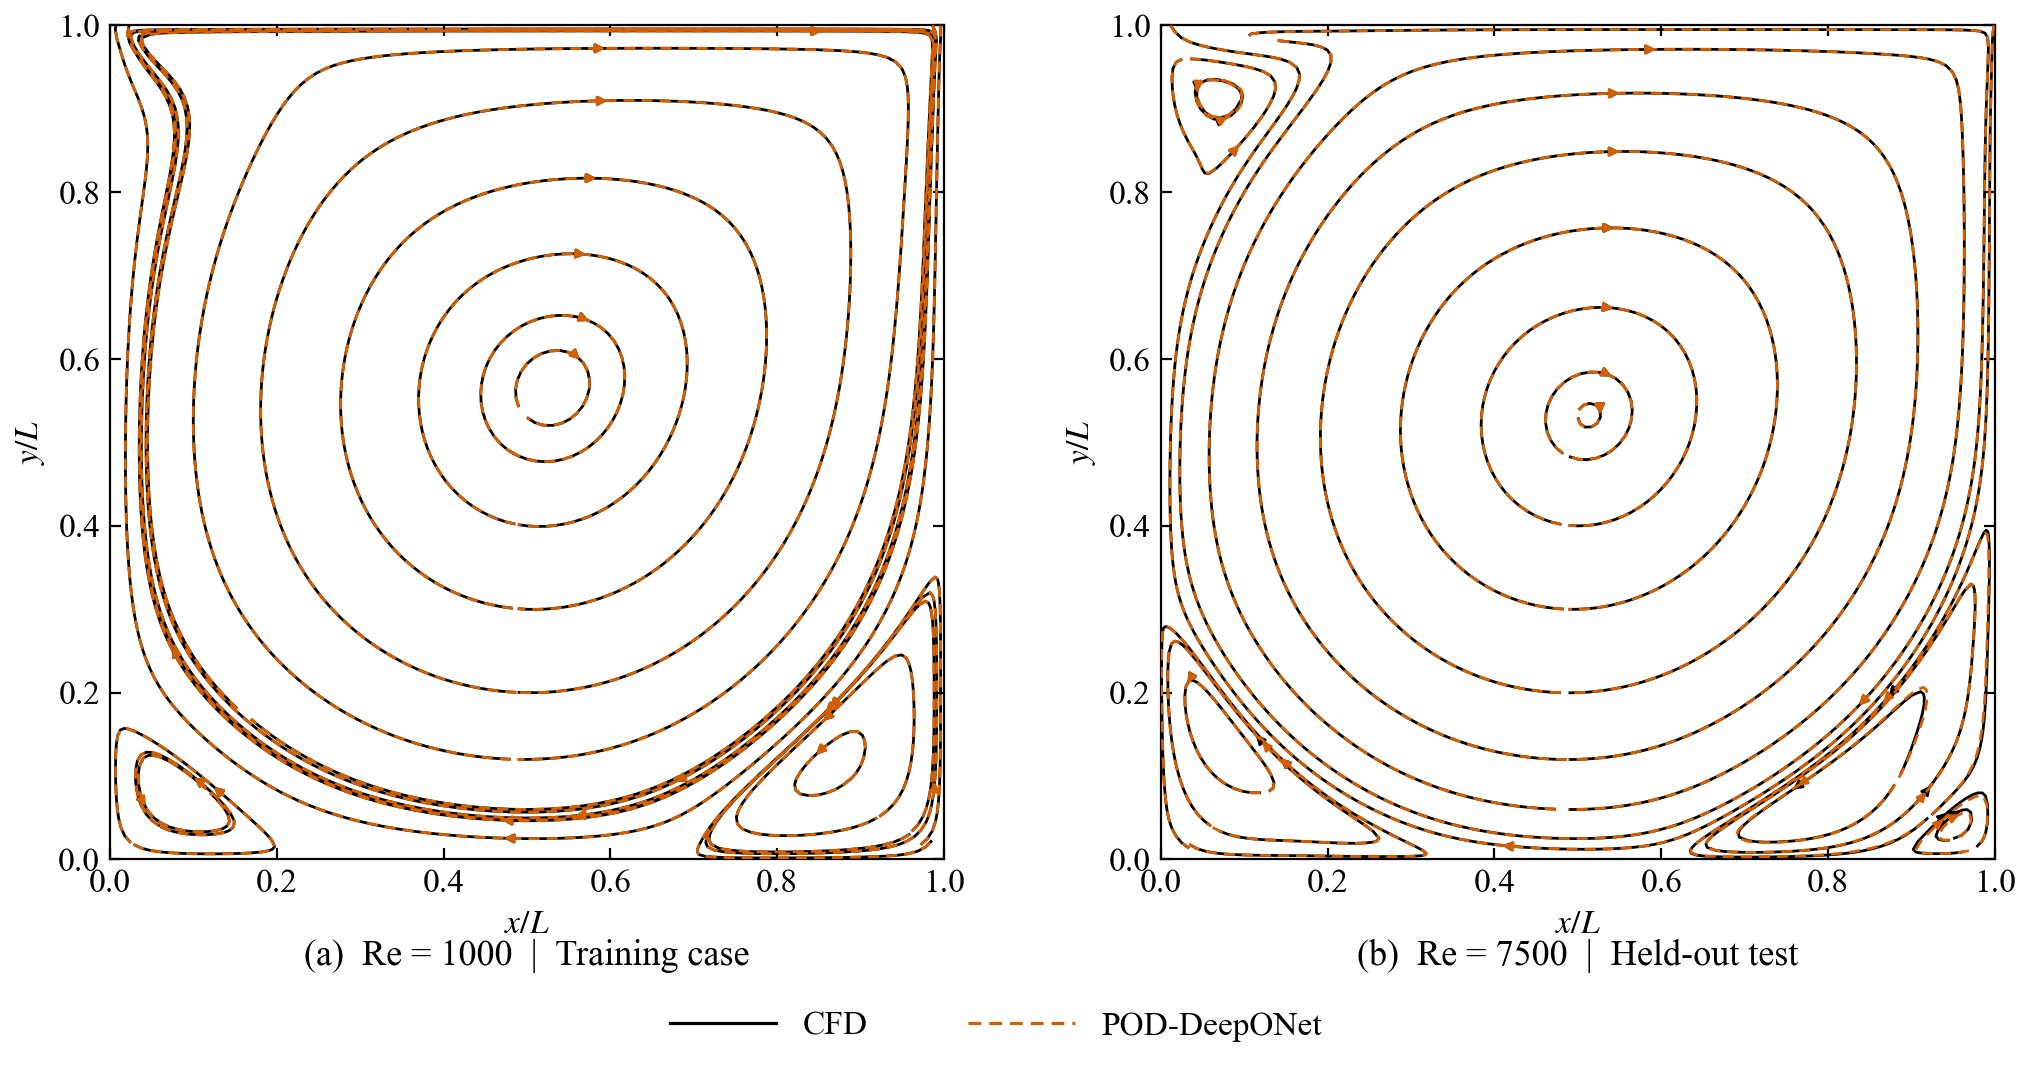

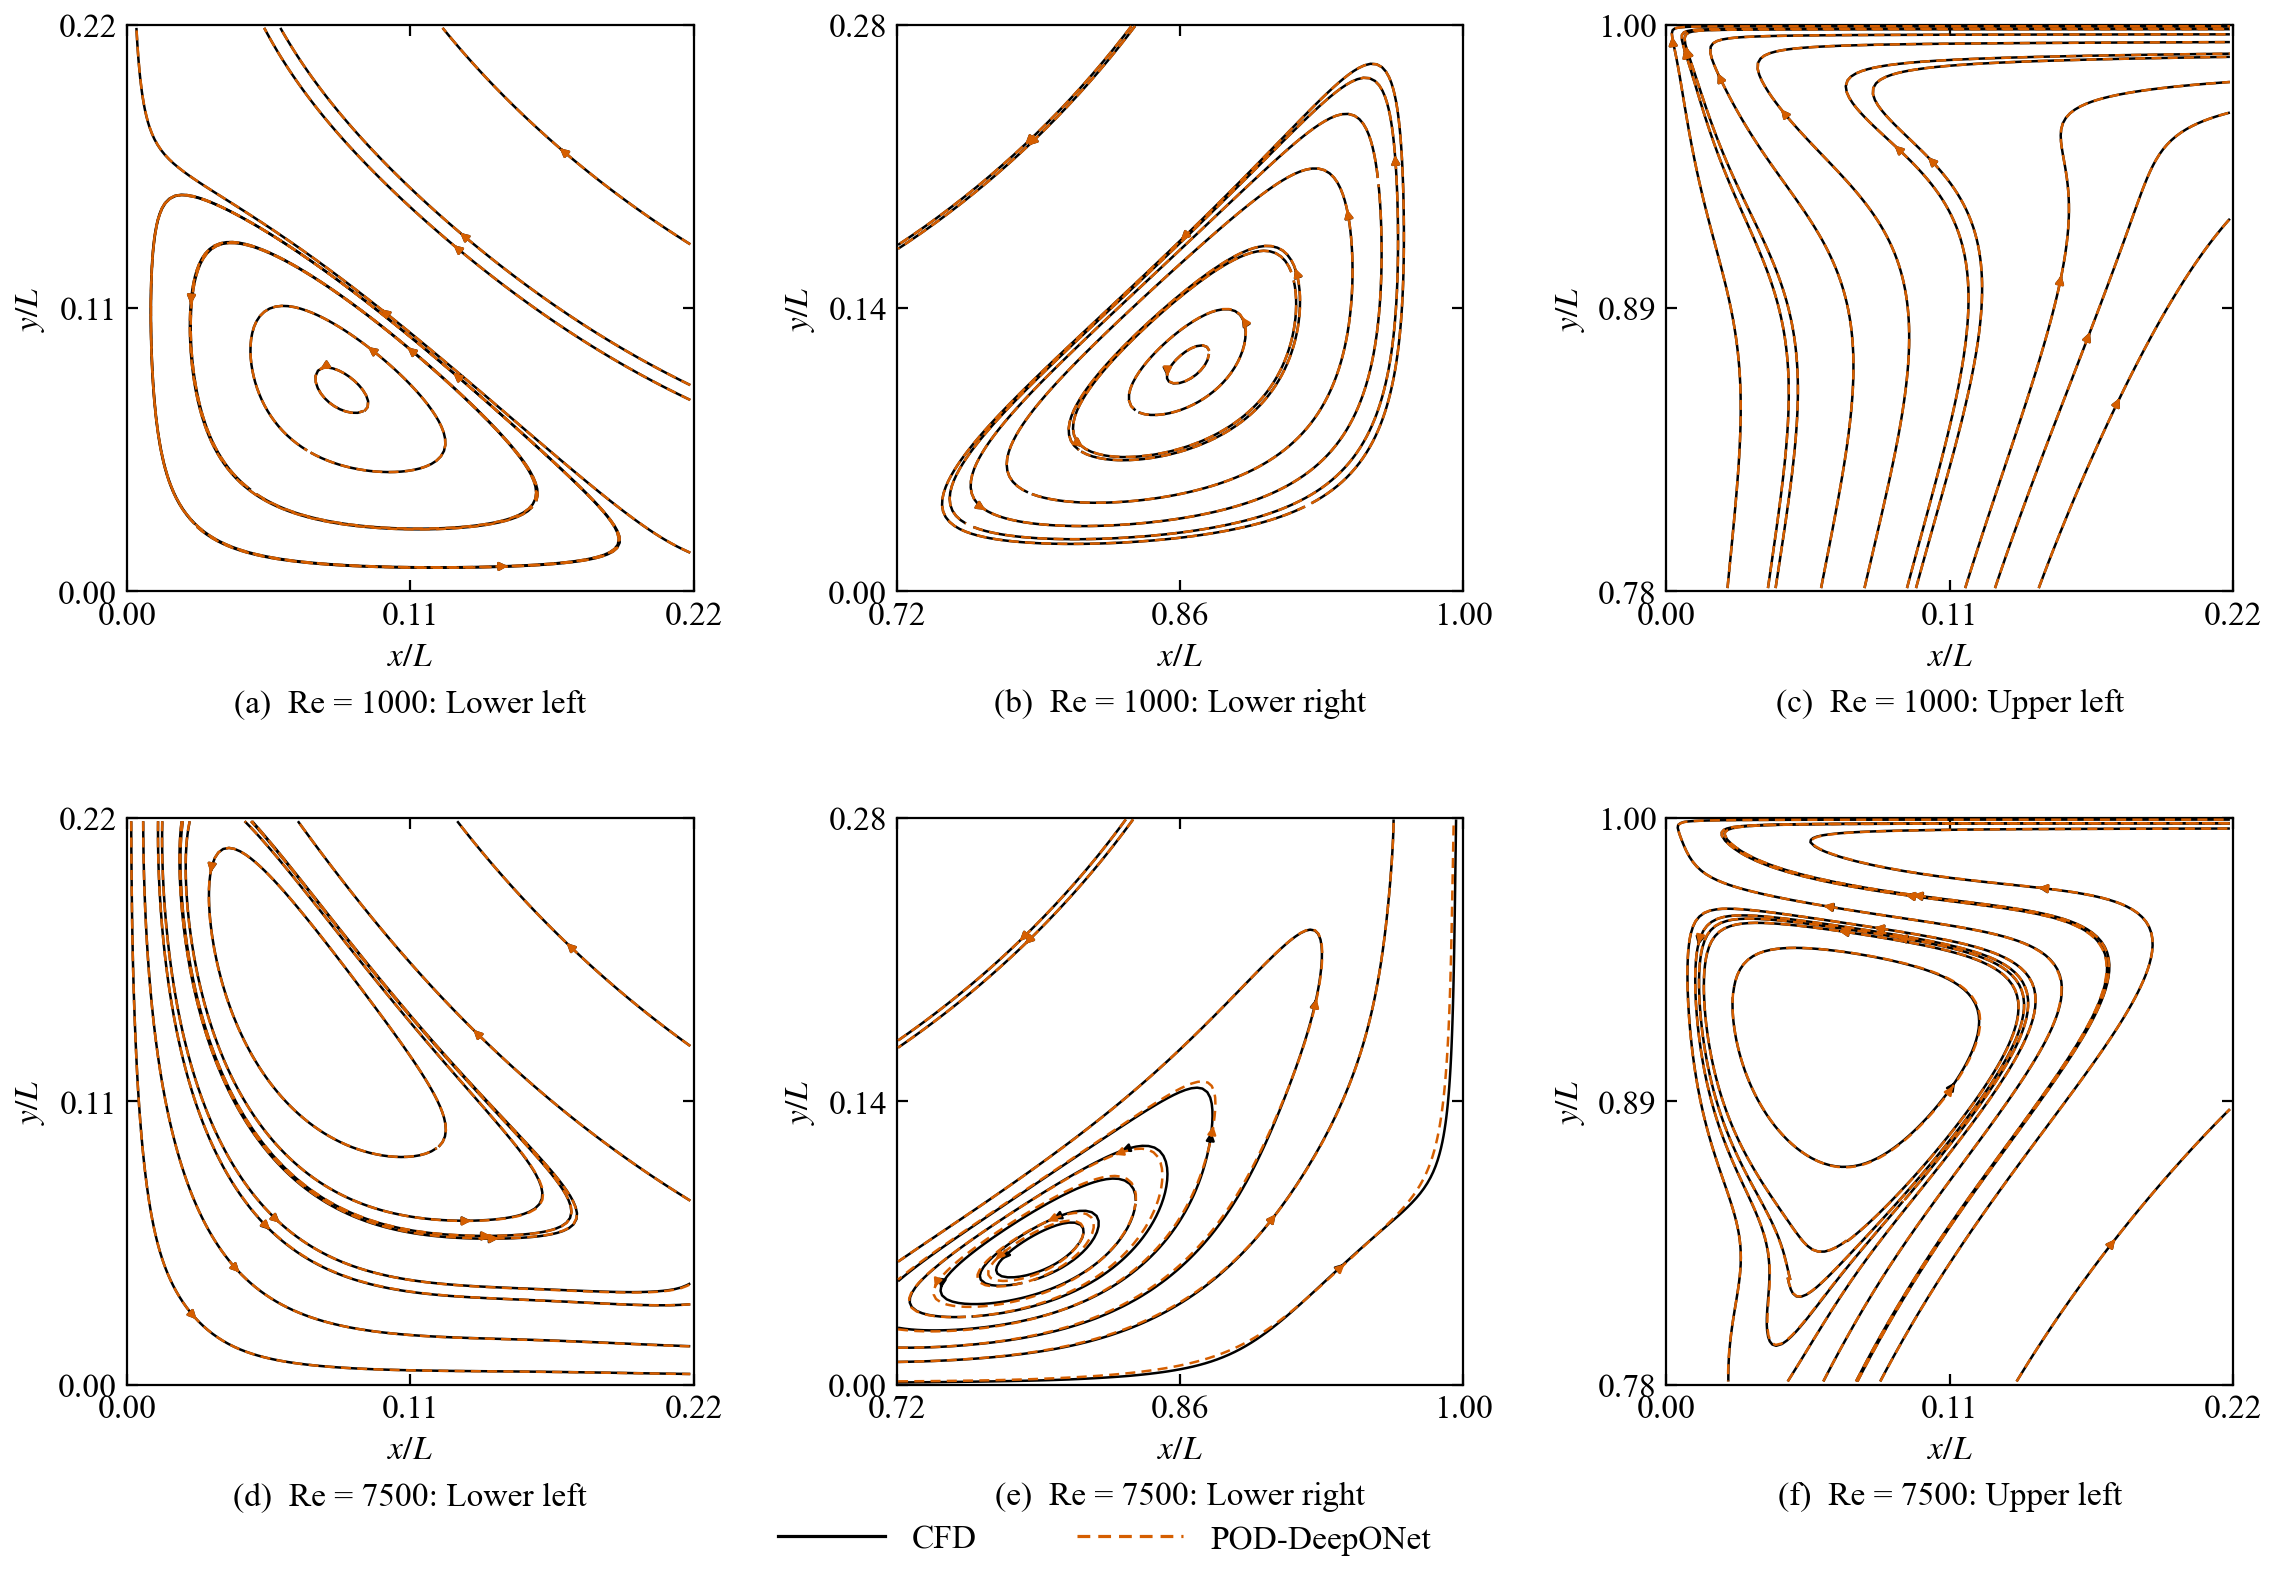

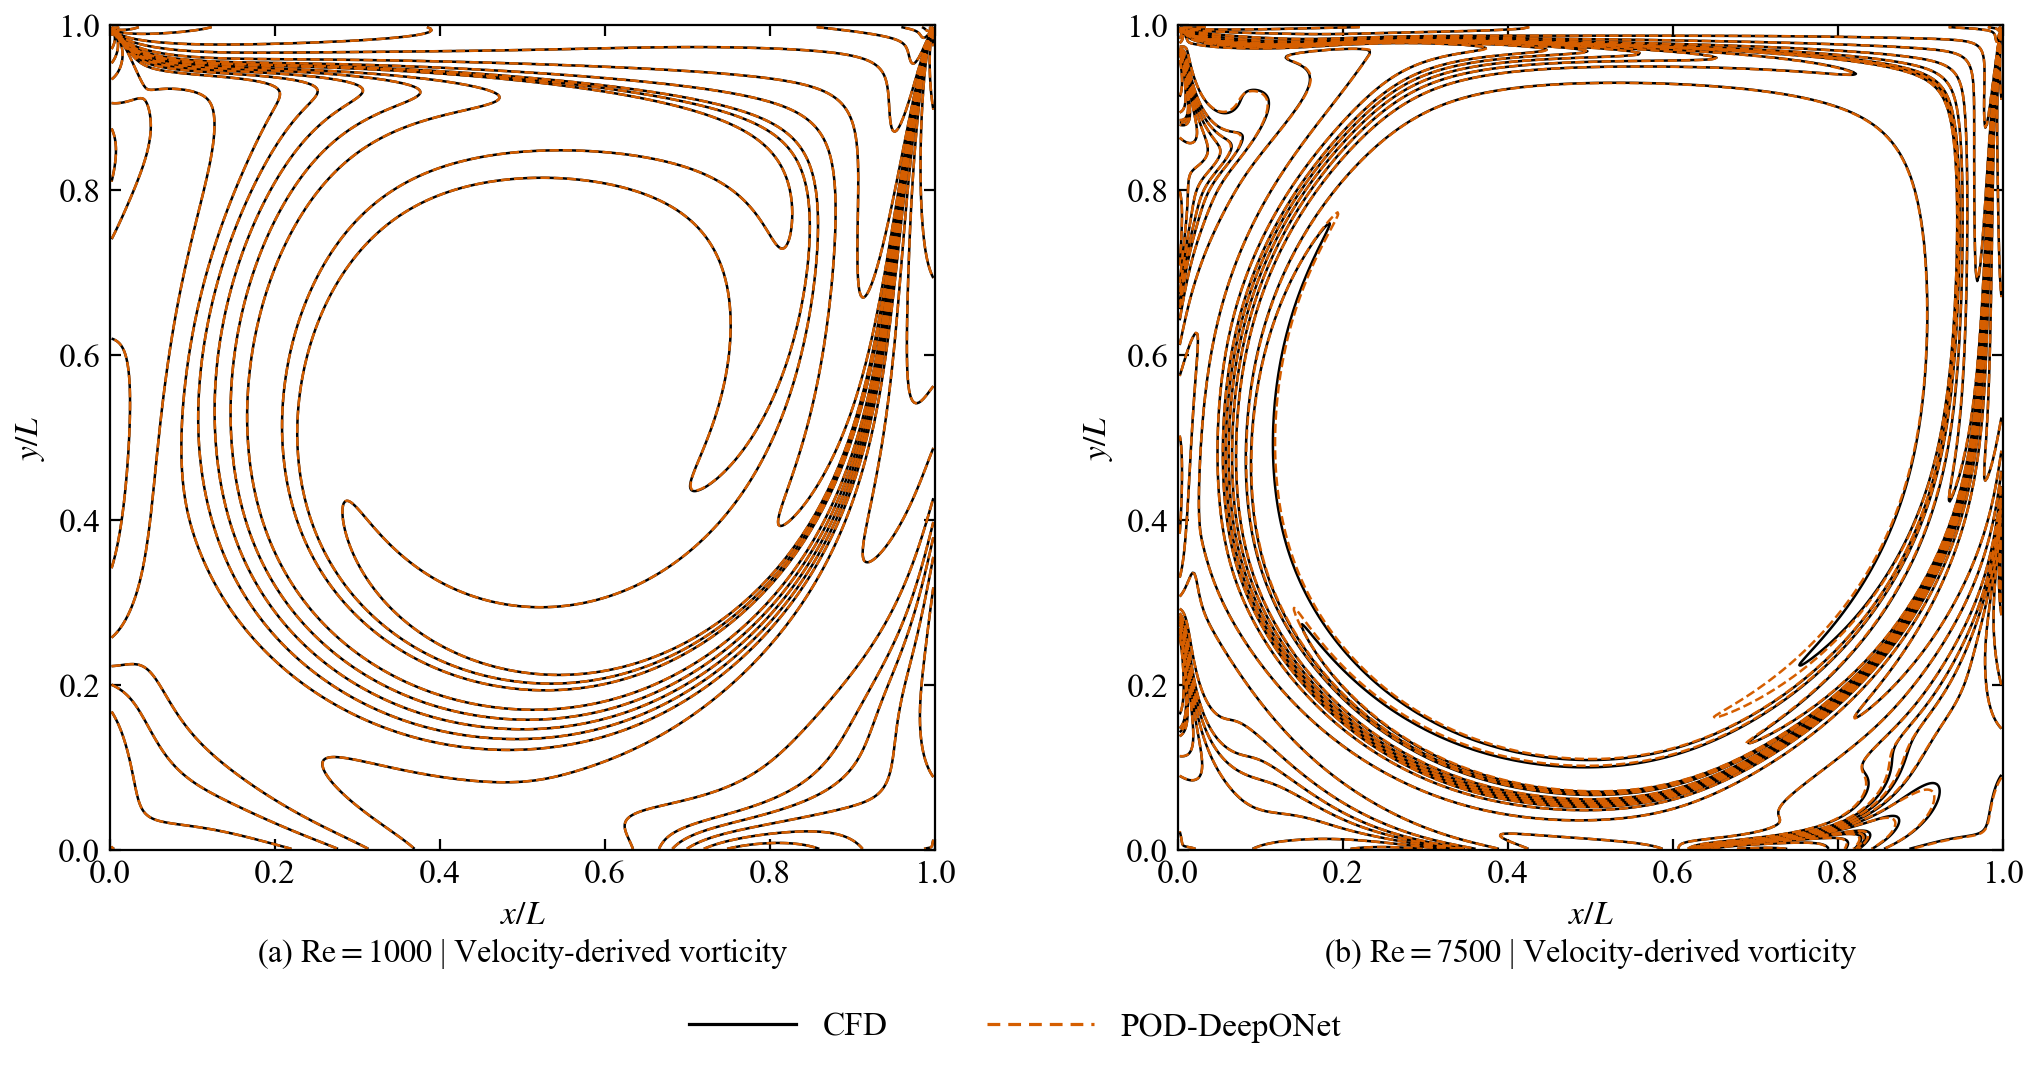

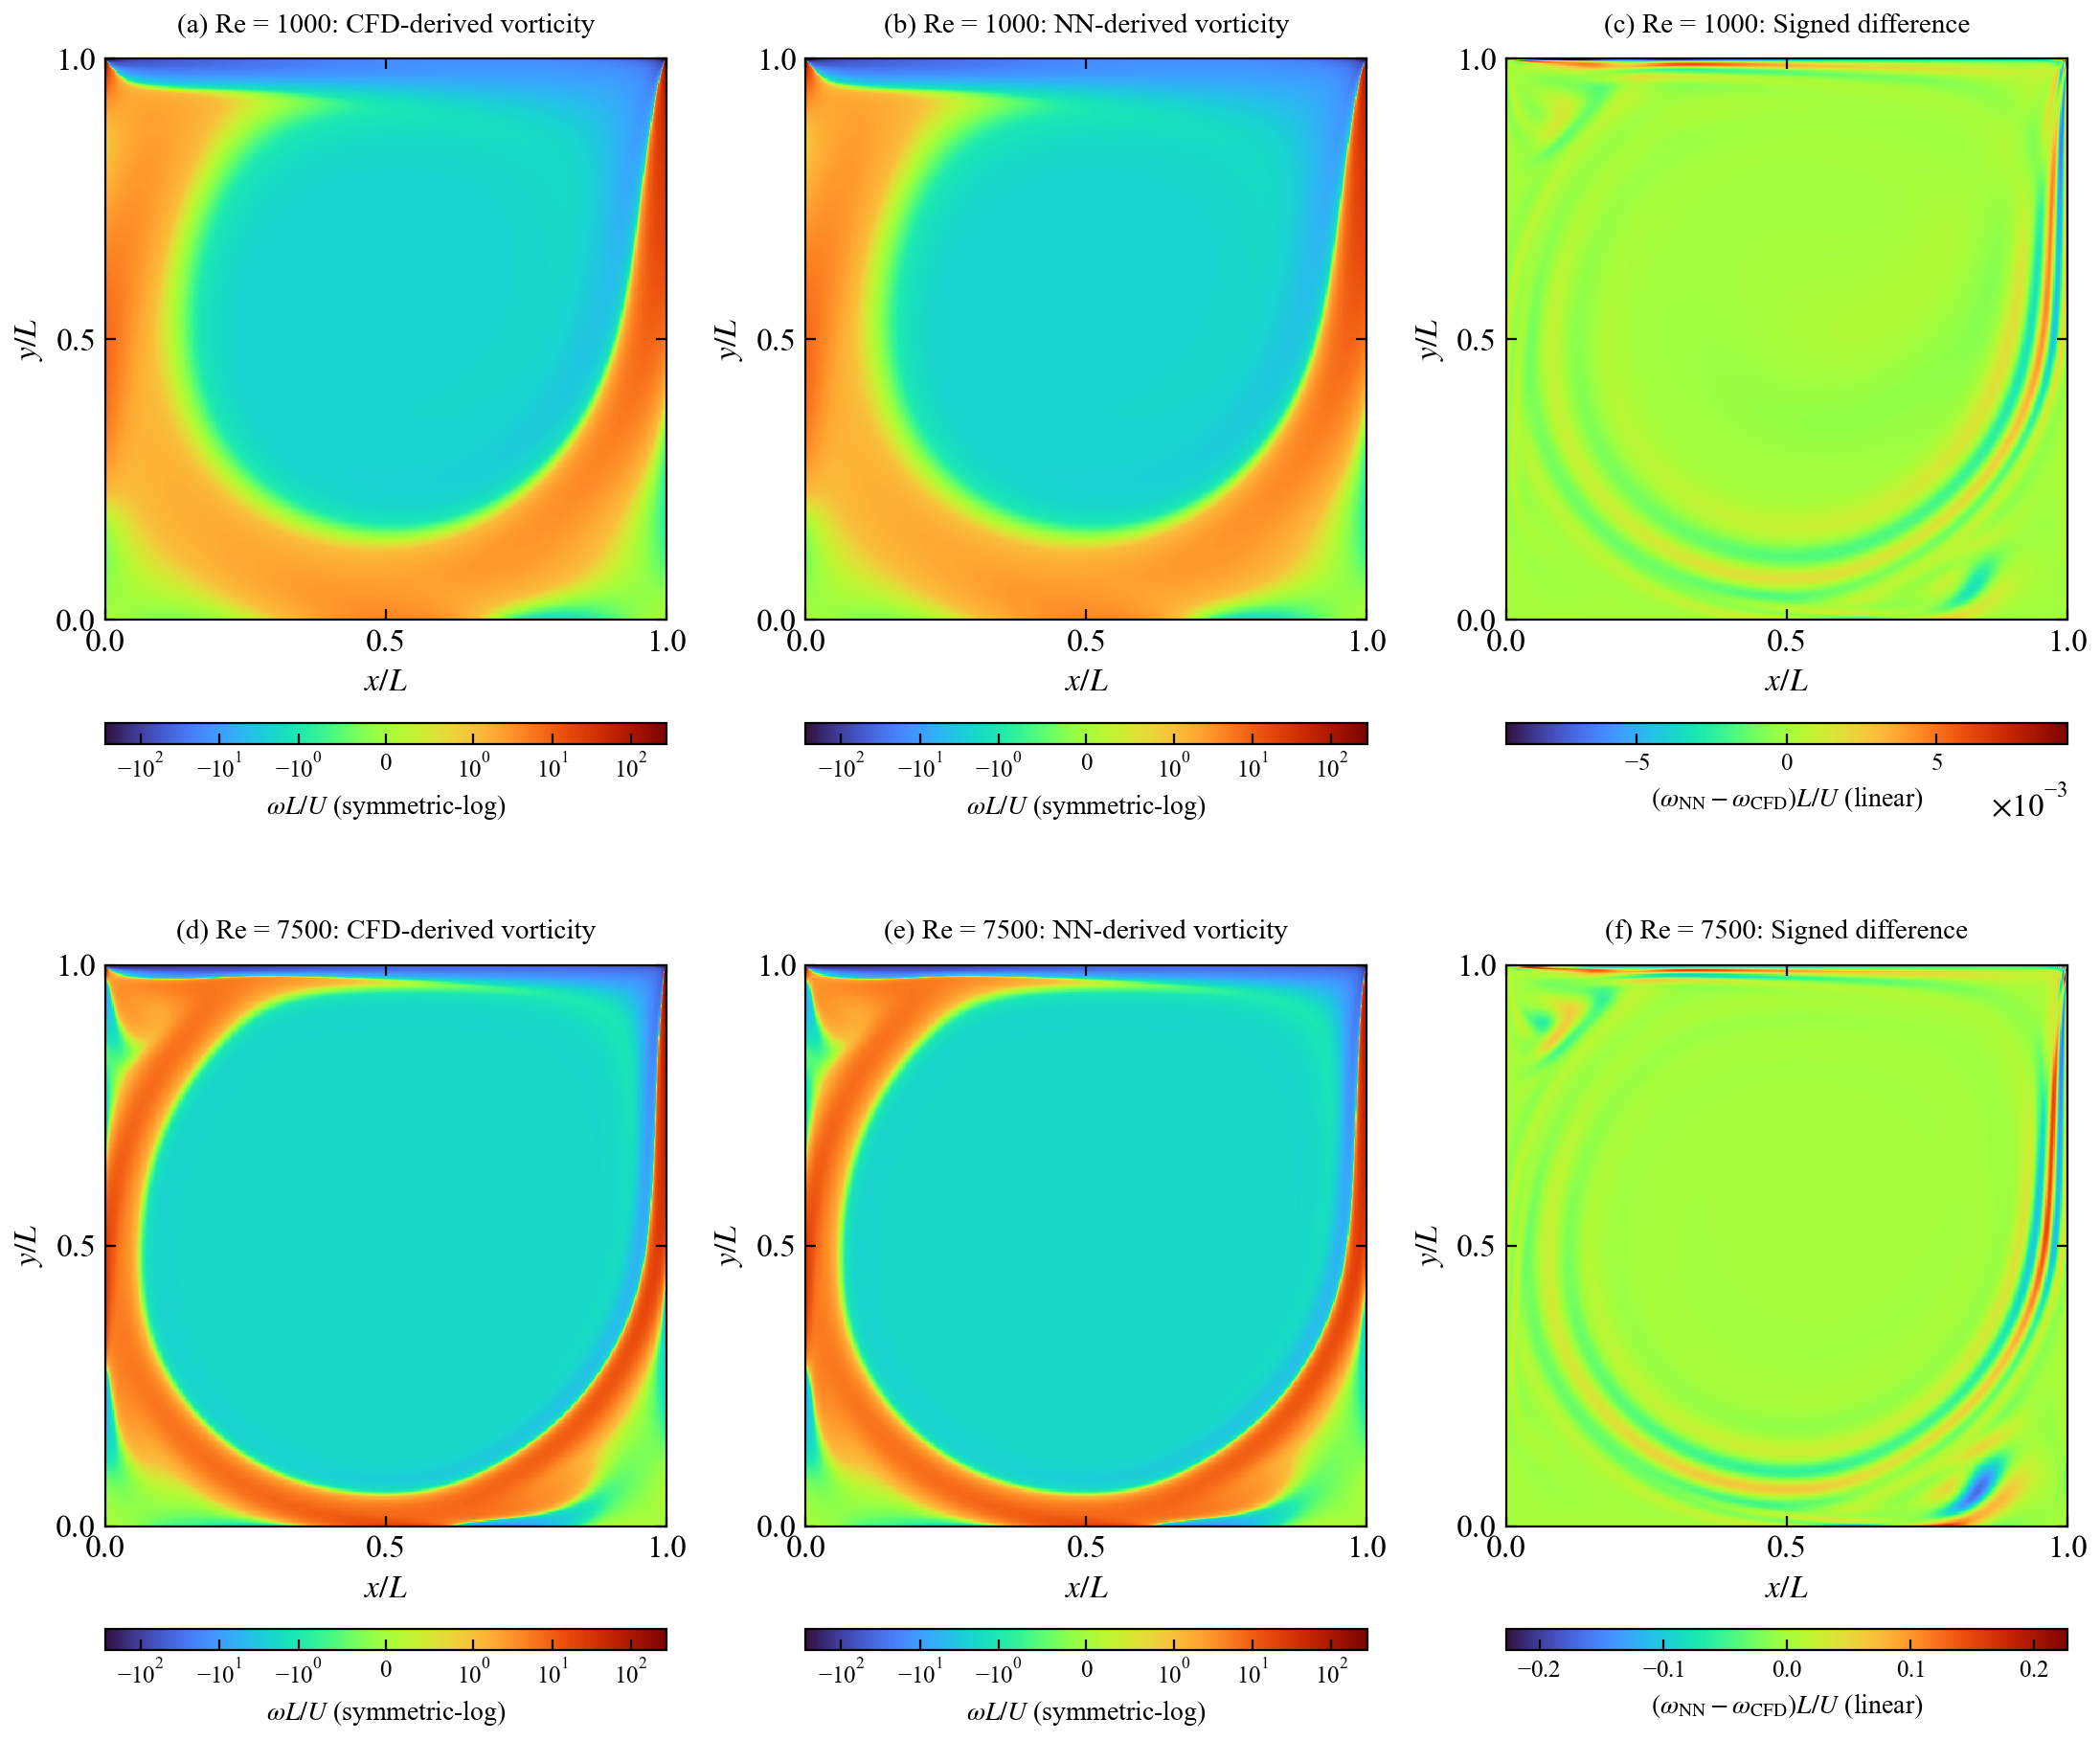

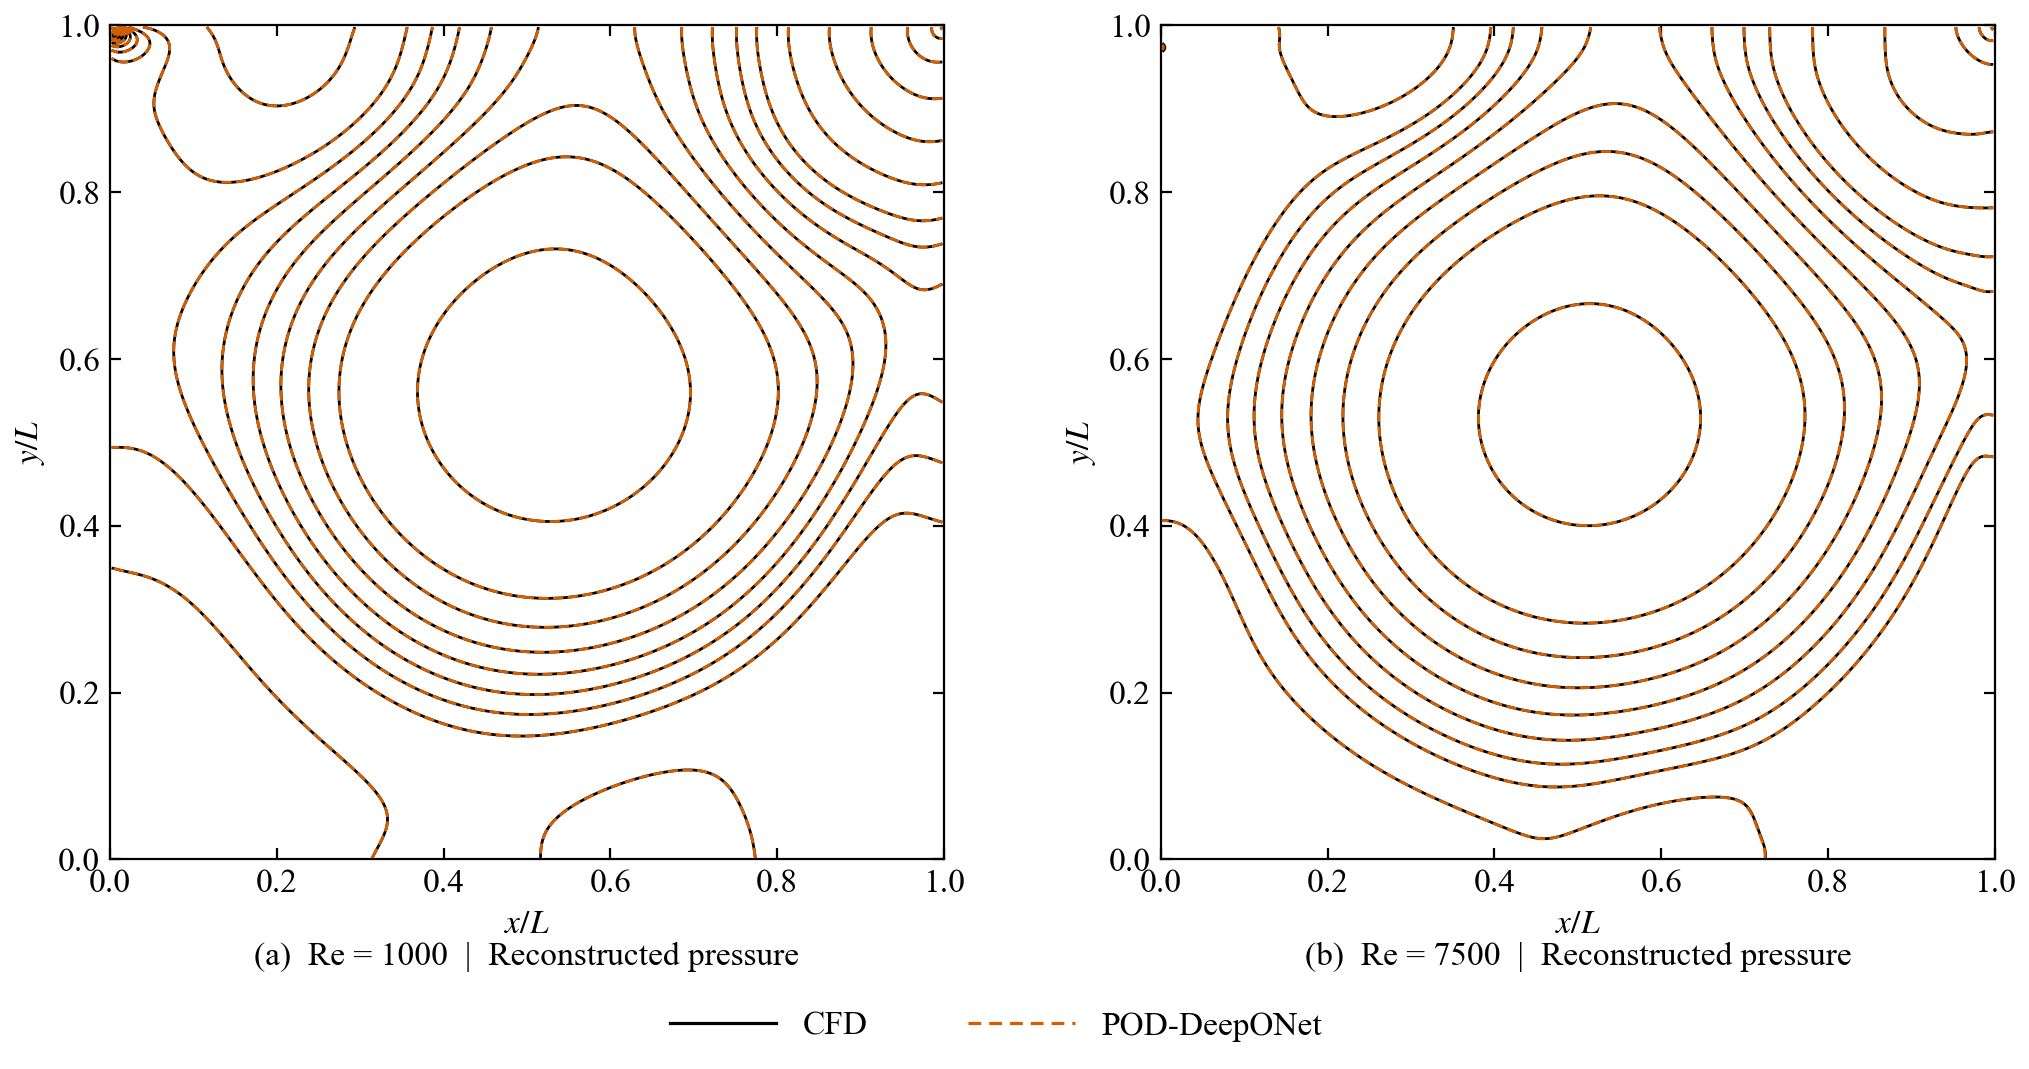

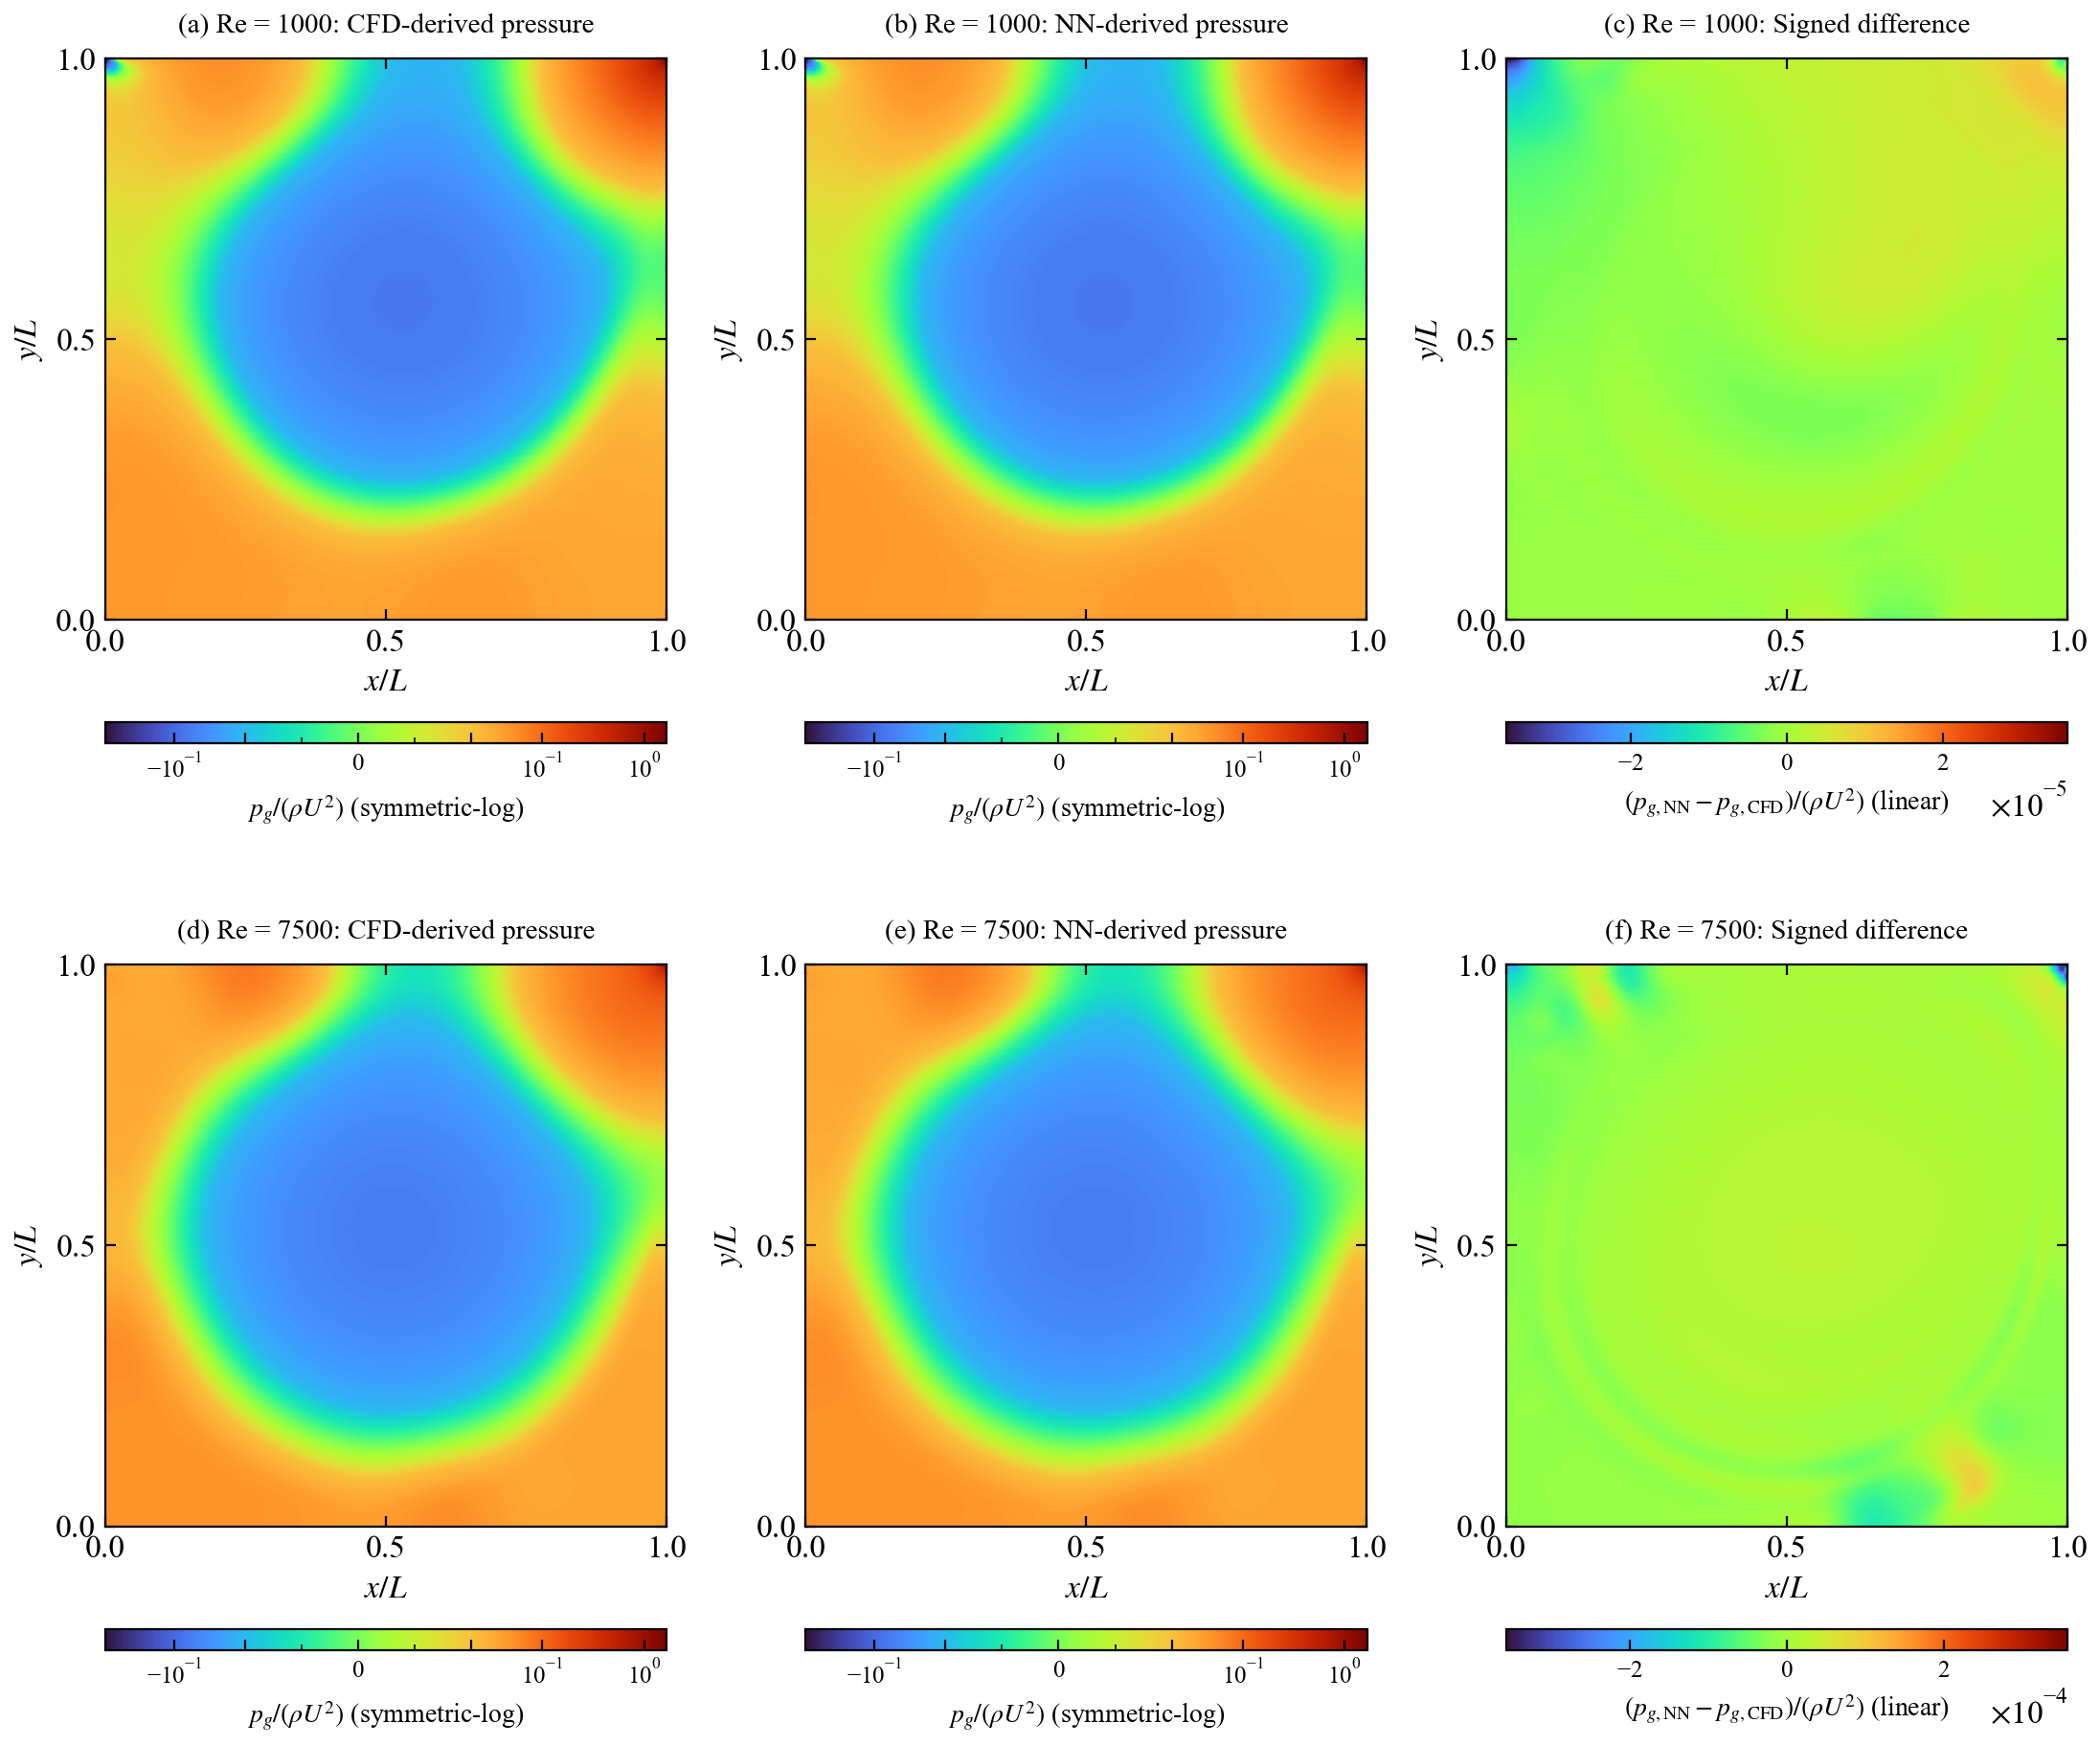

,Re,role,relative_l2,rms,linf,linf_signed,linf_x,linf_y,cfd_min,cfd_max,nn_min,nn_max
0,1000,training,0.000144,0.000824,0.009361,-0.009361,0.123047,0.998047,-283.730681,130.477887,-283.730607,130.471160
1,7500,held_out_test,0.002931,0.023552,0.227148,0.227148,0.996094,0.978516,-266.922381,172.015580,-266.929883,171.992032


,Re,method,role,velocity_relative_l2,pressure_min,pressure_max,pressure_gradient_fit_rms,pressure_gradient_fit_relative,pressure_relative_l2,pressure_rms,pressure_linf
0,1000,CFD,training,0.000000,-0.476215,1.666688,7.314517e-13,9.497672e-13,0.000000,0.000000,0.000000
1,1000,POD-DeepONet,training,0.000036,-0.476251,1.666668,1.545863e-04,2.007280e-04,0.000069,0.000003,0.000036
2,7500,CFD,held_out_test,0.000000,-0.067806,0.809041,2.652296e-12,7.017657e-12,0.000000,0.000000,0.000000
3,7500,POD-DeepONet,held_out_test,0.000844,-0.067781,0.808683,6.503021e-04,1.721435e-03,0.000537,0.000021,0.000358


,Re,cells,pressure_rms,pressure_relative_l2,gauge_offset
0,1000,128,0.002228,0.050570,0.000528
1,1000,256,0.000572,0.012744,0.000177
2,7500,128,0.014669,0.371499,0.000541
3,7500,256,0.003542,0.089011,0.000181


Re7500 independently recomputed vorticity discrepancy: 0.2931%


In [6]:
import hashlib
from flowmllab import cavity_comparison as comparison
GALLERY = OUT/'flow_comparison'
receipt = json.loads((GALLERY/'verification.json').read_text())
for relative, expected in receipt['source_hashes'].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() == expected
for name, expected in receipt['output_sha256'].items():
    assert hashlib.sha256((GALLERY/name).read_bytes()).hexdigest() == expected
for stem in ['streamlines_overlay', 'corner_streamlines_overlay',
             'vorticity_contours_overlay', 'vorticity_fields_and_signed_error',
             'pressure_contours_overlay', 'pressure_fields_and_signed_error']:
    display(Image(filename=str(GALLERY/(stem+'_Re1000_Re7500.png'))))
display(pd.read_csv(GALLERY/'vorticity_metrics.csv'))
display(pd.read_csv(GALLERY/'comparison_metrics.csv'))
display(pd.read_csv(GALLERY/'pressure_mesh_sensitivity.csv'))
# Independently re-evaluate the derivative error on the already-loaded held-out velocities.
fields = cases[7500]
omega_cfd = comparison.vorticity(fields['CFD'])['w']
omega_nn = comparison.vorticity(fields['Selected NN'])['w']
recomputed_error = np.linalg.norm(omega_nn-omega_cfd) / np.linalg.norm(omega_cfd)
recorded = pd.read_csv(GALLERY/'vorticity_metrics.csv').set_index('Re').loc[7500,'relative_l2']
np.testing.assert_allclose(recomputed_error, recorded, rtol=1e-11)
print(f'Re7500 independently recomputed vorticity discrepancy: {100*recomputed_error:.4f}%')

## 7. Historical computing: time, hardware price and run cost

Ghia, Ghia and Shin used an **Amdahl 470 V/6** and coupled strongly implicit
multigrid. They report 1.5 CPU minutes at Re1000 on 129-by-129 nodes, and
16-20 minutes for high-Re cases up to Re10000 on 257-by-257 nodes
([paper, pp. 387 and 410](https://doi.org/10.1016/0021-9991(82)90058-4)).
The [Computer History Museum](https://www.computerhistory.org/revolution/mainframe-computers/7/169/677)
lists this 1975 mainframe at 3.5 MIPS, up to 8 MB and \$3.75 million.
As a dated desktop example, the [October 2024 Mac mini M4 launch](https://www.apple.com/newsroom/2024/10/apples-new-mac-mini-is-more-mighty-more-mini-and-built-for-apple-intelligence/)
started at \$599 with 16 GB and 10 CPU cores. These are nominal hardware prices,
not inflation-adjusted prices or per-solve bills; the Mac did not produce our
Unity timings. MIPS is not modern floating-point throughput.

The table below sums actual one-core Unity Newton-solve wall timers for the
continuation sequence from an available Re1000 seed through Re10000. It excludes
seed creation, queue, transfer, training and temporal checks. Ghia's CPU timing,
initial state and algorithm differ, so dividing those times does not establish
a controlled speedup. No monetary run charge was recorded.

For an explicitly assumed one-core rate $r$ (currency per core-hour), a scenario
cost is $C=r\,t/3600$, with $t$ in seconds. Keep scenario estimates separate
from invoices and from the hardware purchase price.

In [7]:
history = json.loads((GALLERY/'historical_cost_context.json').read_text())
timing = pd.DataFrame(history['flowmllab_timing'])
timing['summed_solve_wall_minutes'] = timing.summed_solve_wall_seconds / 60
display(timing[['nodes', 'core_allocation', 'summed_solve_wall_seconds',
                'summed_solve_wall_minutes', 'last_continuation_step_wall_seconds']])
ASSUMED_RATE_PER_CORE_HOUR = 0.10  # a classroom scenario, NOT Unity's price
scenario = timing[['nodes', 'summed_solve_wall_seconds']].copy()
scenario['illustrative_cost'] = scenario.summed_solve_wall_seconds / 3600 * ASSUMED_RATE_PER_CORE_HOUR
display(scenario)
print('Scenario only: excludes seed creation and all unrecorded costs; not an invoice.')

,nodes,core_allocation,summed_solve_wall_seconds,summed_solve_wall_minutes,last_continuation_step_wall_seconds
0,129,1,29.507425,0.491790,1.488297
1,257,1,277.500543,4.625009,12.111298
2,513,1,2443.006519,40.716775,98.656747


,nodes,summed_solve_wall_seconds,illustrative_cost
0,129,29.507425,0.000820
1,257,277.500543,0.007708
2,513,2443.006519,0.067861


Scenario only: excludes seed creation and all unrecorded costs; not an invoice.


## 8. Engineering exercises and required deliverables

**A — Optimizer/depth/weighting.** Using Section 2, report mean and seed range
at each validation Re for all five configurations. Compare Adam versus hybrid
at fixed depth, two versus five layers, and global versus per-mode scaling.
Identify improvements and deterioration, with parameter counts and evaluation
budgets. Do not select the model using Section 4 tests.

**B — Training information.** Explain the 3.2510% projection floor in Section 3.
Compare first-round and current validation errors after adding Re=500 and 750.
The training information changes; do not attribute this effect to optimization.

**C — Physical error.** For each test Re, report vector and component relative
L2 errors, plus the maximum signed centreline discrepancy and its location.
Compare the selected three-seed mean with both baselines. Report wins and
losses. Supply signed u/v profile plots, not bar charts.

**D — Numerical limits.** From Section 5 compare surrogate error with mesh
sensitivity, and wall/continuity errors with nonlinear residuals. Explain
why none of exact continuity, a small supervised loss or a small mesh
difference alone proves an accurate physical solution.

**E — Deliberate CPU training.** Enable the cell below and change one setting:
depth, width, scaling or Adam budget. Train only on the training POD coefficients
and score validation cases. Record runtime and parameter count. Published test
results are already visible, so further test-based experimentation is exploratory.
Predeclare fresh withheld cases for a new blind research claim.

**F — Flow structure and derivatives.** From Section 6 identify the primary
and corner vortices at both Re. Explain why Re1000 is not a held-out validation.
Report the vorticity L2 and maximum signed discrepancy, including its $(x/L,y/L)$
location. Compare velocity, vorticity and pressure errors with the mesh-sensitivity
rows. Explain why derivatives amplify differences and why the pressure plot is
not an independently trained/validated pressure result. Keep all signs and scales.

**G — Cost accounting.** From Section 7 distinguish the final continuation step
from the complete timed sequence. Recalculate the scenario at 0.05 and 0.50 per
core-hour. List the missing costs and explain why neither a price ratio nor a
ratio of the historical and current timings is a controlled speedup. Explain
what matched grid, tolerance, initialization, precision and timing scope would
be needed for such a claim.

Submit one CSV for A-D and F-G, the two signed physical-profile comparisons, and a short
interpretation separating representation, optimization and discretization errors.
Record software version and model/data hashes.

In [8]:
RUN_NEW_CPU_EXPERIMENT = False
if RUN_NEW_CPU_EXPERIMENT:
    trunk = dict(np.load(OUT/'trunk.npz',allow_pickle=False))
    trial = op.Config('student_trial',depth=3,width=24,optimizer='hybrid',
                      scaling='global',evaluations=2000,adam_evaluations=600)
    model = op.fit(trial,7,trunk['train_coefficients'])
    prediction = op.reconstruct(trunk,op.predict_coefficients(model,op.VALIDATION))
    rows = []
    for j,reynolds in enumerate(op.VALIDATION):
        data = np.load(ROOT/f'results/cavity_highre_ghia/n512/re{reynolds}.npz',allow_pickle=False)
        truth = np.r_[data['u'].ravel(),data['v'].ravel()]
        rows.append({'Re':reynolds,**op.velocity_error(prediction[j],truth)})
        nn = len(data['x']); shape = (len(data['y']), nn); size = shape[0]*shape[1]
        up, vp = prediction[j,:size].reshape(shape), prediction[j,size:].reshape(shape)
        preds = {'Current student POD-DeepONet': (up,vp)}
        figures = w4plots.velocity_comparison(data['x'],data['y'],data['u'],data['v'],
                                               preds,reynolds,'new validation fit')
        figures += [w4plots.velocity_profiles(data['x'],data['y'],data['u'],data['v'],
                                               preds,reynolds,'new validation fit')]
        for suffix,fig in zip(('velocity','profiles'),figures):
            save_current_figure(fig,f'lab8_current_validation_Re{reynolds}_{suffix}')
            plt.show();plt.close(fig)
    display(pd.DataFrame(rows))
    print('Parameters:',len(model['theta']),'seconds:',model['training_seconds'])
else:
    print('No training requested; frozen results remain unchanged.')

No training requested; frozen results remain unchanged.


## 9. Measured CFD cost: a solver change that did not pay off

The [new final section of Lab 7](W4_Lab7_High_Re_CFD_Ghia.ipynb) records an actual
matched experiment: keep the steady cavity equations, grids, seeds and outer
Newton iteration, but replace sparse direct factorization with GMRES and a
multigrid preconditioner. The candidate took **1.95-2.17 times as long** in four
warm-case/grid comparisons. Rebuilding the strong ILUT hierarchy consumed
**89.3-95.2%** of solve time (ratios of medians), despite only eight total GMRES
iterations and the same four Newton steps. Our production CFD solver is retained.

These are the costs of **generating discrete CFD labels**, not training times,
neural inference times, or neural accuracy gains. No network was retrained in
this experiment, no train/validation/test split changed, and no new optimizer
was tested on the neural loss. A faster label generator would not itself lower
the neural prediction error or resolve the mesh uncertainty discussed above.

Three warm repetitions per method start from matched $Re=6500$ or $9000$
fields, targeting $Re=7500$ or $10000$. The 257-node full continuation path has
one repetition per method. All used one CPU thread on an Intel Xeon Gold 5220
node. Timing includes setup but excludes seed generation, queues, I/O and
verification; it is not an end-to-end dataset-production invoice. The candidate
has a stricter additional inner residual check, while final acceptance is shared.

The following CPU-only cell verifies the evidence-file hashes and the recorded
input hashes/pair identity, then recalculates the table. It does not reload the
original seed NPZ files from the full benchmark archive. See the [full report](../../results/cavity_solver_benchmark/README.md)
and the end of the [Week 4 lecture](../../lectures/week04_cavity_surrogates_deeponet.pdf)
for failures, equations, tolerances and limitations. This is one candidate
implementation; it is not a reproduction of Ghia's strongly implicit multigrid.

In [9]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Independent of neural-model imports; also runs from a notebook subdirectory.
bench_candidates = [Path(p) for p in [globals().get('ROOT'), Path.cwd(),
                    *Path.cwd().parents, Path('/content/FlowMLLab')] if p is not None]
bench_root = next((p for p in bench_candidates
                   if (p/'results/cavity_solver_benchmark/manifest.json').is_file()), None)
if bench_root is None:
    raise FileNotFoundError('Use the complete updated FlowMLLab checkout.')
BENCH = bench_root/'results/cavity_solver_benchmark'
bench_manifest = json.loads((BENCH/'manifest.json').read_text(encoding='utf-8-sig'))
for name, expected in bench_manifest['sha256'].items():
    assert hashlib.sha256((BENCH/name).read_bytes()).hexdigest() == expected, name
bench_evidence = json.loads((BENCH/'evidence.json').read_text(encoding='utf-8-sig'))
bench_trials = bench_evidence['trials']
production_trials = [e['result'] for e in bench_trials if e['path'].startswith('production/')]
assert len(production_trials) == 26

# Match inputs and numerical policy BEFORE calculating a performance ratio.
identity_keys = ['seed_sha256', 'reference_sha256', 'packed_initial_state_sha256',
                 'host', 'slurm_job_id', 'environment', 'thread_environment',
                 'schedule', 'nonlinear_tolerance', 'source_sha256_lf', 'candidate_config']
paired_runs = {}
for run in production_trials:
    key = (run['cells'], run['scenario'], run['repeat'])
    paired_runs.setdefault(key, {})[run['method']] = run
assert len(paired_runs) == 13
for key, pair in paired_runs.items():
    assert set(pair) == {'direct', 'gmres_mg'}, key
    direct, mg = pair['direct'], pair['gmres_mg']
    for name in identity_keys:
        assert direct[name] == mg[name], (key, name)
    for run in (direct, mg):
        assert run['success'] and run['final_residual_linf'] < 1e-8
        assert set(run['thread_environment'].values()) == {'1'}
        assert run['reference_discrepancies']['velocity_relative_l2'] < 1e-8
        assert run['reference_discrepancies']['omega']['relative_l2'] < 1e-7
        assert all(s['success'] and s['original_relative_defect'] <= 1e-5
                   for s in run['linear_solves'])

# One row per actual run; never put failed pilot runs in successful timing medians.
trial_timing = pd.DataFrame([{
    'nodes': run['nodes'], 'scenario': run['scenario'], 'method': run['method'],
    'repeat': run['repeat'], 'wall_s': run['solve_wall_seconds'],
    'setup_s': run['profiling']['preconditioner_setup_seconds'],
    'newton_steps': sum(h['newton_iterations'] for h in run['history']),
    'gmres_iterations': run['profiling']['krylov_iterations'],
    'peak_rss_MiB': run['peak_rss_KiB']/1024,
} for run in production_trials])
bench_timing = trial_timing.groupby(['nodes', 'scenario', 'method']).agg(
    repetitions=('wall_s', 'size'), median_s=('wall_s', 'median'),
    minimum_s=('wall_s', 'min'), maximum_s=('wall_s', 'max'),
    setup_median_s=('setup_s', 'median'),
    newton_steps_median=('newton_steps', 'median'),
    gmres_iterations_median=('gmres_iterations', 'median'),
    peak_rss_MiB=('peak_rss_MiB', 'max')).reset_index()
bench_comparison = bench_timing.pivot(index=['nodes', 'scenario'], columns='method', values='median_s')
bench_comparison['MG_over_direct'] = bench_comparison.gmres_mg / bench_comparison.direct
bench_comparison.columns.name = None
print('Verified evidence-file hashes and recorded input hashes/pair identity for 13 pairs (26 successful main trials).')
display(bench_timing[['nodes', 'scenario', 'method', 'repetitions', 'median_s', 'minimum_s', 'maximum_s']])
display(bench_comparison)

Verified evidence-file hashes and recorded input hashes/pair identity for 13 pairs (26 successful main trials).


,nodes,scenario,method,repetitions,median_s,minimum_s,maximum_s
0,257,continuation,direct,1,247.442013,247.442013,247.442013
1,257,continuation,gmres_mg,1,561.950467,561.950467,561.950467
2,257,warm10000,direct,3,14.854675,14.522826,15.257235
3,257,warm10000,gmres_mg,3,28.998392,28.540719,29.298747
4,257,warm7500,direct,3,14.247829,14.223867,14.679699
5,257,warm7500,gmres_mg,3,29.270279,29.228729,29.543665
6,513,warm10000,direct,3,133.804384,133.435665,136.642175
7,513,warm10000,gmres_mg,3,273.300556,269.880109,273.741709
8,513,warm7500,direct,3,130.157873,127.245380,134.147537
9,513,warm7500,gmres_mg,3,283.005024,279.991094,293.303689


direct    gmres_mg  MG_over_direct
nodes scenario                                            
257   continuation  247.442013  561.950467        2.271039
      warm10000      14.854675   28.998392        1.952139
      warm7500       14.247829   29.270279        2.054368
513   warm10000     133.804384  273.300556        2.042538
      warm7500      130.157873  283.005024        2.174321

### Engineering exercise H - Account for the entire surrogate workflow

Use the measured `bench_comparison` table to explain why replacing the label
solver with this candidate would increase the measured solve cost. Report the
four warm ratios and distinguish them from the single continuation ratio.
Keep these matched November 15 timings separate from the earlier historical
comparison in Section 7, which used different runs and initialization schedules.

For $M$ future queries, write a cost ledger

$$T_{\rm surrogate}(M)=T_{\rm labels}+T_{\rm train}+M\,t_{\rm infer},\qquad
T_{\rm CFD}(M)=M\,t_{\rm CFD}.$$

Here $T_{\rm labels}$ is total label-generation cost, $T_{\rm train}$ training and
selection cost, $t_{\rm infer}$ cost per neural query, and $t_{\rm CFD}$ a comparable
CFD query cost. If $t_{\rm CFD}>t_{\rm infer}$, the break-even condition is
$M>(T_{\rm labels}+T_{\rm train})/(t_{\rm CFD}-t_{\rm infer})$.
List which terms are measured, missing, or incomplete in this notebook. Explain
why a warm continuation timer cannot automatically stand in for an arbitrary
new CFD query. Do not invent an inference time or numerical break-even count;
state what a fair future measurement must include.

Finally, compare solver-to-solver agreement (maximum full-grid velocity relative
$L_2$ discrepancy $2.11\times10^{-14}$ over five representative field pairs) with
the actual held-out neural error and mesh sensitivity above. These are different
quantities. Submit a one-page cost ledger and a numerical timing table, with the
manifest hash. No rerun or training is required; further model selection must
still keep the disclosed test cases out of fitting and tuning.